# Final held-out evaluation

The analysis evaluates the frozen EfficientNet-B0 U-Net comparisons on RID's southwest region and WHU's provider test set. It asks whether the validation observations about initialization, labelled-image count and training budget persist on held-out geography. Models and checkpoint-selection rules were fixed before test inference; no further training or test-driven tuning is performed.

## Evaluation design

The [prospective protocol](../docs/final_evaluation_protocol.md) specifies 36 primary checkpoints: two datasets, three training sizes, three saved subsets and two initializations. Six additional RID checkpoints address image selection. Twenty entries compare validation-selected checkpoints through 4,000 and 8,000 updates within the same extended training runs. These 62 entries represent 52 trained models.

RID's primary population contains 254 tiles. Five historically exposed or overlapping tiles are excluded prospectively; the complete 259-tile region is a sensitivity analysis. WHU includes all 2,416 test tiles. RID labels describe visible roofs, whereas WHU labels describe building footprints; absolute scores across datasets are not directly comparable.

Inference uses native images, saved normalization, batch size four, float32 and probability threshold 0.5. Checkpoints were selected using validation IoU only. Mean per-image foreground intersection-over-union (IoU) is primary. Dice and non-interpolated pixel average precision (AP) are secondary. AP is averaged over positive-reference images. Empty reference and prediction score one for IoU/Dice; any foreground prediction on an empty reference scores zero. Empty-reference diagnostics are therefore reported separately.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
results = pd.read_csv(ROOT / "reports/final_test_results.csv")
paired = pd.read_csv(ROOT / "reports/final_test_paired.csv")
summary = pd.read_csv(ROOT / "reports/final_test_summary.csv")
execution = json.loads((ROOT / "reports/final_test_execution.json").read_text())
assert execution["completed"] and execution["checkpoint_entries"] == 62

## Primary learning curves

Each point summarizes three training-image selections; bars show sample standard deviation (SD, ddof=1). Model, ordering and augmentation seeds are fixed. SD measures sensitivity to subset selection on shared test geography, rather than all training randomness or a confidence interval. All individual paired scores remain visible below.

,dataset,training_size,random_mean,random_std,imagenet_mean,imagenet_std,imagenet_minus_random_mean
1,rid,25,0.7530,0.0358,0.8153,0.0250,0.0622
3,rid,100,0.8032,0.0109,0.8538,0.0046,0.0505
5,rid,500,0.8182,0.0030,0.8683,0.0006,0.0501
6,whu_aerial,25,0.6711,0.0169,0.7314,0.0074,0.0603
7,whu_aerial,100,0.7381,0.0028,0.8054,0.0039,0.0673
8,whu_aerial,500,0.7703,0.0059,0.8298,0.0142,0.0596


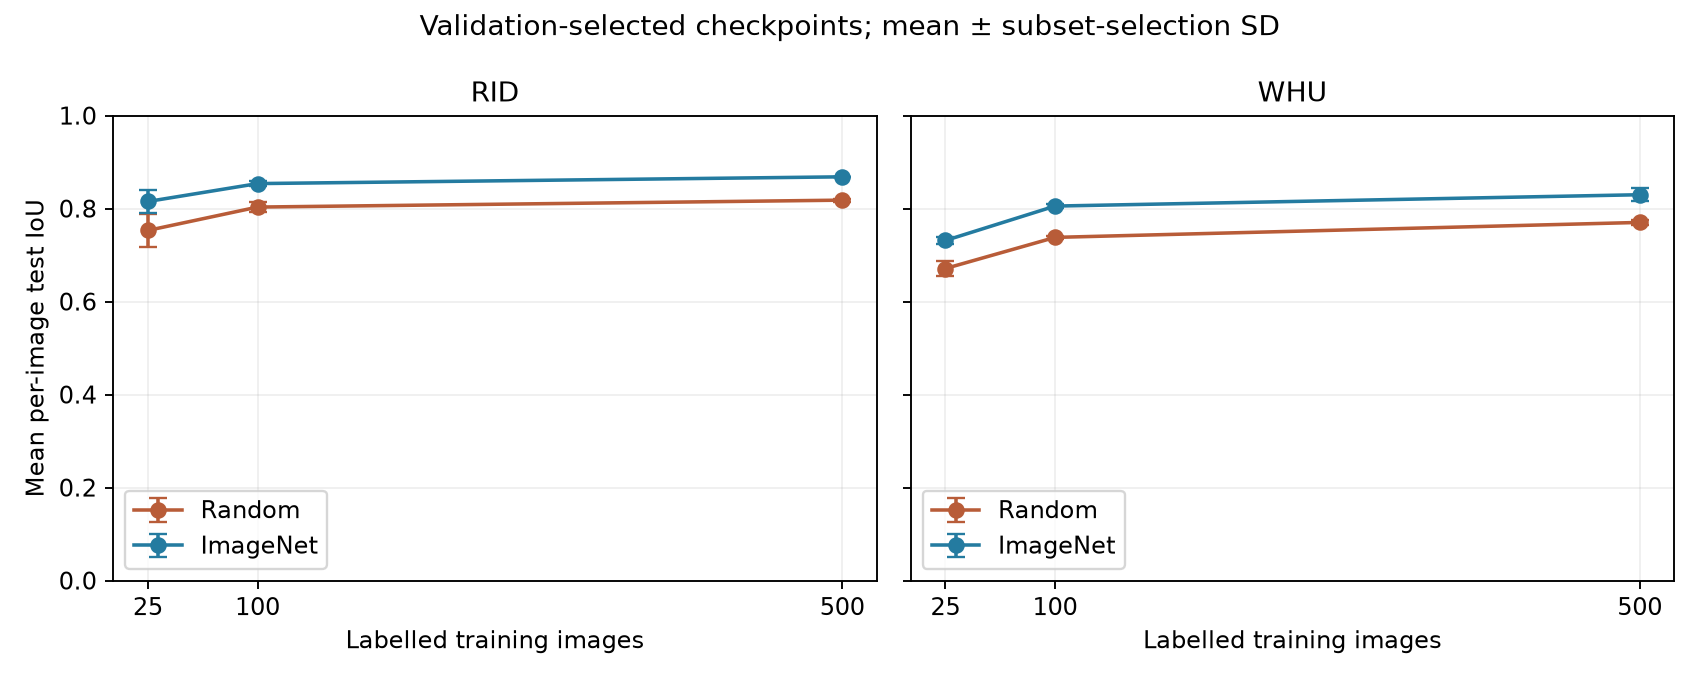

In [2]:
primary = summary.query("analysis == 'primary_learning_curve' and population == 'primary'")
columns = ["dataset", "training_size", "random_mean", "random_std", "imagenet_mean", "imagenet_std", "imagenet_minus_random_mean"]
display(primary[columns].round(4))
display(Image(filename=str(ROOT / "reports/figures/08_final_test_learning_curves.png")))

In [3]:
individual = paired.query("analysis == 'primary_learning_curve' and population == 'primary'")
display(individual[["dataset", "training_size", "subset_seed", "random", "imagenet", "imagenet_minus_random"]].round(4))

,dataset,training_size,subset_seed,random,imagenet,imagenet_minus_random
1,rid,25,17,0.7686,0.8222,0.0536
3,rid,25,29,0.7784,0.8361,0.0577
5,rid,25,43,0.7121,0.7876,0.0754
7,rid,100,17,0.8121,0.8585,0.0463
9,rid,100,29,0.8065,0.8494,0.0429
11,rid,100,43,0.7911,0.8534,0.0623
13,rid,500,17,0.8156,0.8689,0.0533
15,rid,500,29,0.8174,0.8682,0.0508
17,rid,500,43,0.8215,0.8678,0.0463
18,whu_aerial,25,17,0.6536,0.7234,0.0698


ImageNet initialization leads in **18 of 18** primary paired test comparisons. The observed differences concern this architecture and these test regions; subset SD does not establish statistical significance.

## Positive and empty reference images

IoU on positive-reference images complements the all-image average. For empty references, the foreground fraction and the fraction of images with any prediction describe false-positive behavior. An absent group is undefined, not assigned an artificial zero score.

In [4]:
reference_groups = results.query("analysis == 'primary_learning_curve' and population == 'primary'")
group_means = reference_groups.groupby(["dataset", "training_size", "initialization"]).mean(numeric_only=True)
positive = group_means[["positive_image_count", "positive_mean_iou", "positive_mean_dice", "mean_average_precision"]]
positive = positive.rename(columns={
    "positive_image_count": "Images", "positive_mean_iou": "IoU",
    "positive_mean_dice": "Dice", "mean_average_precision": "AP",
})
positive["Images"] = positive["Images"].astype(int)
display(positive.round(4))

Images     IoU    Dice      AP
dataset    training_size initialization                                
rid        25            imagenet           254  0.8153  0.8938  0.9379
                         random             254  0.7530  0.8521  0.9139
           100           imagenet           254  0.8538  0.9178  0.9551
                         random             254  0.8032  0.8865  0.9411
           500           imagenet           254  0.8683  0.9269  0.9664
                         random             254  0.8182  0.8962  0.9500
whu_aerial 25            imagenet          1731  0.7503  0.8374  0.9049
                         random            1731  0.6771  0.7840  0.8648
           100           imagenet          1731  0.7958  0.8677  0.9316
                         random            1731  0.7324  0.8230  0.9045
           500           imagenet          1731  0.8170  0.8832  0.9476
                         random            1731  0.7573  0.8430  0.9195

In [5]:
empty = group_means[["empty_image_count", "empty_mean_foreground_fraction", "empty_fraction_with_any_prediction"]]
empty = empty.rename(columns={
    "empty_image_count": "Images", "empty_mean_foreground_fraction": "Foreground fraction",
    "empty_fraction_with_any_prediction": "Any prediction fraction",
})
empty["Images"] = empty["Images"].astype(int)
display(empty.round(4))

Images  Foreground fraction  \
dataset    training_size initialization                                
rid        25            imagenet             0                  NaN   
                         random               0                  NaN   
           100           imagenet             0                  NaN   
                         random               0                  NaN   
           500           imagenet             0                  NaN   
                         random               0                  NaN   
whu_aerial 25            imagenet           685               0.0024   
                         random             685               0.0071   
           100           imagenet           685               0.0011   
                         random             685               0.0042   
           500           imagenet           685               0.0016   
                         random             685               0.0032   

                                         Any prediction fraction  
dataset    training_size initialization                           
rid        25            imagenet                            NaN  
                         random                              NaN  
           100           imagenet                            NaN  
                         random                              NaN  
           500           imagenet                            NaN  
                         random                              NaN  
whu_aerial 25            imagenet                         0.3163  
                         random                           0.3440  
           100           imagenet                         0.1703  
                         random                           0.2477  
           500           imagenet                         0.1377  
                         random                           0.1971

WHU contains 1,731 positive and 685 empty references; RID's 254 primary references all contain roofs. At n=500, the mean fraction of empty WHU images with any predicted foreground is 13.8% for ImageNet and 19.7% for Random. The ImageNet advantage also remains on positive-reference IoU and AP, so it is not explained solely by empty images. RID has no empty-reference group, so those diagnostics are undefined.

## Training-budget sensitivity

The following comparison pairs the best validation-selected checkpoint through 4,000 updates with the best through 8,000 in the *same fresh extended run*. It measures the resulting test performance under two selection budgets (40 versus 80 opportunities). These are not fixed-update endpoint predictions: final-update weights were not generally retained. RID has two subset repetitions, WHU three.

In [6]:
budget = results.query("analysis == 'secondary_budget' and population == 'primary'")
budget_pairs = budget.pivot(index=["dataset", "subset_seed", "initialization"], columns="selection_through_update", values="mean_iou")
budget_pairs["change_8000_minus_4000"] = budget_pairs[8000] - budget_pairs[4000]
display(budget_pairs.round(4))

selection_through_update                 4000    8000  change_8000_minus_4000
dataset    subset_seed initialization                                        
rid        17          imagenet        0.8689  0.8707                  0.0017
                       random          0.8156  0.8196                  0.0040
           29          imagenet        0.8682  0.8768                  0.0086
                       random          0.8174  0.8244                  0.0070
whu_aerial 17          imagenet        0.8428  0.8411                 -0.0017
                       random          0.7705  0.7749                  0.0044
           29          imagenet        0.8147  0.8281                  0.0133
                       random          0.7642  0.7801                  0.0159
           43          imagenet        0.8319  0.8261                 -0.0057
                       random          0.7761  0.7899                  0.0138

Mean test-IoU changes from the 4,000-selection range to 8,000 were RID: Random +0.0055, ImageNet +0.0052; WHU: Random +0.0114, ImageNet +0.0019. Random benefits more from the extended selection budget on WHU, while the two initializations have similar mean gains on RID. The initialization advantage persists under both budgets.

## Image selection and RID history sensitivity

RID's secondary n=100 comparison contrasts uniform-random selection with spatial maximin selection. Training-image coverage and overlap change together, so this does not isolate a causal effect of geographic spacing. The full-region sensitivity includes five tiles with known historical development exposure; it supplements the primary population and does not replace it.

In [7]:
selection = paired.query("dataset == 'rid' and training_size == 100 and population == 'primary' and analysis != 'secondary_budget'")
display(selection[["subset_seed", "selection_strategy", "random", "imagenet", "imagenet_minus_random"]].round(4))
rid_history = results.query("dataset == 'rid'").pivot(index=["analysis", "training_size", "subset_seed", "initialization", "selection_through_update"], columns="population", values="mean_iou")
rid_history["full_minus_primary"] = rid_history["full_region_sensitivity"] - rid_history["primary"]
display(rid_history.groupby(level="analysis")["full_minus_primary"].agg(["min", "max", "mean"]).round(4))
# Individual differences are saved in reports/final_test_rid_sensitivity.csv.

,subset_seed,selection_strategy,random,imagenet,imagenet_minus_random
7,17,spatial_maximin,0.8121,0.8585,0.0463
9,29,spatial_maximin,0.8065,0.8494,0.0429
11,43,spatial_maximin,0.7911,0.8534,0.0623
42,17,uniform_random,0.8147,0.8678,0.0531
44,29,uniform_random,0.7925,0.8579,0.0654
46,43,uniform_random,0.8116,0.8598,0.0482


,min,max,mean
analysis,,,
primary_learning_curve,0.0004,0.0018,0.0010
secondary_budget,0.0008,0.0011,0.0009
secondary_selection,0.0008,0.0016,0.0011


The mean spatial-minus-uniform test-IoU difference at n=100 is -0.0030 for Random and -0.0081 for ImageNet. Coverage, overlap and selected imagery change together; this is a descriptive selection comparison.

The full RID region changes individual IoUs by +0.0004 to +0.0018 relative to the primary population. The five historically exposed/overlapping tiles remain excluded from the primary result.

## Qualitative interpretation

The frozen example rule uses n=100 and seed 17 for each dataset. It selects the two lowest and two highest positive-reference paired mean IoUs, one example nearest the median, and (if present) the empty reference with the largest paired mean foreground fraction. Both initializations appear on the same images. These are metric-selected cases, not representative random samples. Example IDs are saved in `reports/final_test_qualitative_ids.csv`.

Source-image panels remain local in `.local/final_test_figures/` pending clarification of redistribution permissions; the quantitative learning curves are included above. 

In WHU examples `test/26` and `test/175`, both models miss very small labelled structures (IoU zero). The median case `test/2_292` shows closer alignment for ImageNet, while the empty-reference storage/container scene `test/2_1521` elicits foreground predictions from both models. This may involve target-definition or annotation ambiguity; the empty-reference scoring rule remains unchanged.

RID example `2071` shows visible disagreement between the aerial image and reference foreground. Annotation misalignment or incompleteness is a possible explanation, not a verified finding. Both models have low IoU on this case, while the high-IoU cases have closer visual agreement. No label is repaired, reclassified or excluded after test access.

## Limitations and reproducibility

Training-image selection repetitions share evaluation geography and sometimes training images. Repeated validation reuse, fixed non-subset seeds, historical RID exposure and unverifiable tile-level WHU coordinates limit generalization claims. Additional validation labels and ImageNet pretraining are outside the reported target-task training-image count. Neither dataset establishes transfer to an unseen city by an already trained model.

No universal minimum annotation budget, statistical significance, scaling law or convergence is claimed. Later model changes would be post-test exploration. The [execution record](../reports/final_test_execution.json) identifies the executed code commit, device, software, fixed input identities and output hashes. The [setup guide](../docs/setup.md) gives explicit evaluation commands. 

## Conclusion

The frozen test evaluation is complete. ImageNet leads in 18/18 primary paired comparisons. The two datasets provide separate geographic evaluations, rather than a single pooled score. Training-budget and image-selection comparisons help qualify the pretraining effect; they do not justify selecting another model after test access. Further experiments would be a new, explicitly post-test study.